In [2]:
import numpy as np 
import matplotlib.pyplot as plt
def true_function(x):
    return np.sin(1.5*x)+0.5*x

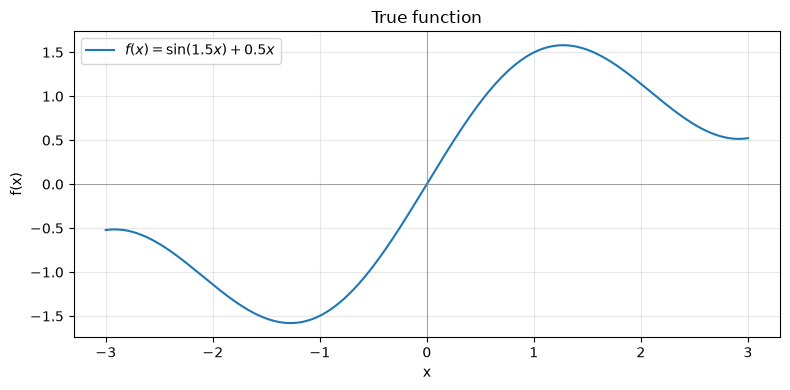

In [3]:
x=np.linspace(-3,3,400)
y=true_function(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, label=r"$f(x) = \sin(1.5x) + 0.5x$", color="tab:blue")
plt.axhline(0, color="gray", linewidth=0.5)   # x-axis reference
plt.axvline(0, color="gray", linewidth=0.5)   # y-axis reference
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("True function")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
import random
def generate_data(n_samples=30,noise_std=0.5,x_range=(-3,3),seed=42):
    rng=np.random.RandomState(seed)
    x=rng.uniform(x_range[0],x_range[1],n_samples)
    y=true_function(x) + rng.normal(0,noise_std,n_samples)
    return x,y

In [5]:
x, y = generate_data(n_samples=30, seed=0)
assert x.shape == (30,) and y.shape == (30,)
assert x.min() >= -3 and x.max() <= 3

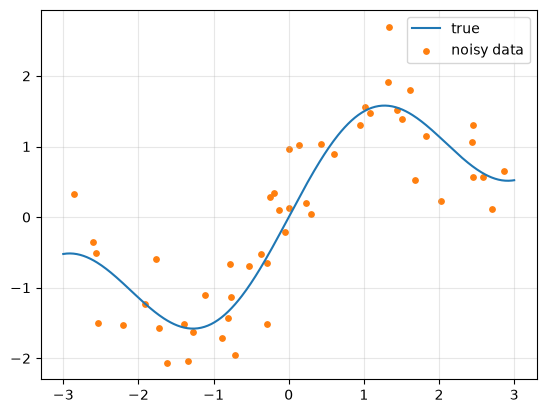

In [6]:
x_clean = np.linspace(-3, 3, 400)
plt.plot(x_clean, true_function(x_clean), label="true", color="tab:blue")

x, y = generate_data(n_samples=50, noise_std=0.5, seed=7)
plt.scatter(x, y, color="tab:orange", s=15, label="noisy data")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [7]:
import numpy as np


def fit_polynomial(x_train, y_train, degree, lam=0.0):
    """
    Fit a degree-`degree` polynomial to (x_train, y_train).
    If lam > 0, use ridge regression (intercept not penalized).
    Returns weight vector w of length degree + 1.
    """
    # --- Build the design matrix X, shape (n, degree+1) ---
    # Column j holds x**j, so row i is [1, x_i, x_i^2, ..., x_i^degree]
    X = np.column_stack([x_train ** d for d in range(degree + 1)])
    #       ^ shape (n,) for each d  →  column_stack makes (n, degree+1)
    #       d=0 gives x**0 = 1 (the intercept column)

    if lam == 0.0:
        # --- Ordinary least squares ---
        # lstsq returns several items; [0] is the solution vector w.
        w = np.linalg.lstsq(X, y_train, rcond=None)[0]

    else:
        # --- Ridge regression ---
        # Normal equation: (X^T X + λI') w = X^T y
        # where I' is the identity with [0,0] set to 0 (intercept unpenalized).
        XtX = X.T @ X                             # shape (degree+1, degree+1)
        penalty = lam * np.eye(degree + 1)        # λ·I
        penalty[0, 0] = 0.0                       # do NOT penalize intercept
        Xty = X.T @ y_train                       # shape (degree+1,)
        w = np.linalg.solve(XtX + penalty, Xty)   # solve the linear system

    return   w                                       # shape (degree+1,)

In [8]:
if __name__ == "__main__":
    # Test 1: exact recovery on a known line
    x = np.linspace(-2, 2, 20)
    y = 2.0 + 3.0 * x
    w = fit_polynomial(x, y, degree=1)
    print("Test 1 — exact line, degree 1:")
    print("  w =", w, "   expected ≈ [2.0, 3.0]")

    # Test 2: ridge shrinks slope but NOT intercept
    w = fit_polynomial(x, y, degree=1, lam=100.0)
    print("\nTest 2 — same data, ridge lam=100:")
    print("  w =", w)
    print("  intercept w[0] should still be ≈ 2")
    print("  slope    w[1] should be shrunk toward 0")

    # Test 3: shape check across degrees
    x, y = np.random.randn(30), np.random.randn(30)  # any data, just check shape
    for d in [1, 3, 5, 9]:
        w = fit_polynomial(x, y, degree=d)
        print(f"\nTest 3 — degree {d}: w.shape = {w.shape}  (expected ({d+1},))")

Test 1 — exact line, degree 1:
  w = [2. 3.]    expected ≈ [2.0, 3.0]

Test 2 — same data, ridge lam=100:
  w = [2.         0.68292683]
  intercept w[0] should still be ≈ 2
  slope    w[1] should be shrunk toward 0

Test 3 — degree 1: w.shape = (2,)  (expected (2,))

Test 3 — degree 3: w.shape = (4,)  (expected (4,))

Test 3 — degree 5: w.shape = (6,)  (expected (6,))

Test 3 — degree 9: w.shape = (10,)  (expected (10,))


In [9]:
x, y = generate_data(n_samples=200, noise_std=0.5, seed=0)
w = fit_polynomial(x, y, degree=1)
print("Degree 1 fit on noisy data:", w)

Degree 1 fit on noisy data: [0.0179853  0.46708322]


In [15]:
x=np.array([1,2,3])
degree=2
np.column_stack([x**d for d in range(degree+1)])

array([[1, 1, 1],
       [1, 2, 4],
       [1, 3, 9]])

In [10]:
def predict_polynomial(x,w):
    degree=len(w)-1 
    X=np.column_stack([x**d for d in range(degree+1)])
    return X@w

In [11]:
x = np.linspace(-2, 2, 20)
y = 2.0 + 3.0 * x
w = fit_polynomial(x, y, degree=1)
pred = predict_polynomial(x, w)
print("max |pred - y| =", np.max(np.abs(pred - y)))
# expected: ~1e-14 (machine precision — a line fits a line exactly)

max |pred - y| = 2.6645352591003757e-15


In [12]:
x_new = np.array([-1.0, 0.0, 1.0, 2.0])   # 4 points, different from training
pred = predict_polynomial(x_new, w)        # use same w from above
print(pred)                                # expected: [-1, 2, 5, 8]  (2 + 3x)

[-1.  2.  5.  8.]


In [16]:
x_train, y_train = generate_data(n_samples=100, noise_std=0.5, seed=0)
w = fit_polynomial(x_train, y_train, degree=3)
pred = predict_polynomial(x_train, w)
print("train MSE =", np.mean((pred - y_train)**2))
# should be fairly small (< noise²=0.25 is possible, but a few times smaller than
# a degree-1 fit's MSE is a good sign)

train MSE = 0.3082098570945985


In [22]:
x_test = np.linspace(-3, 3, 200)
x_train, y_train = generate_data(30, 0.5, (-3, 3), seed=0)
w = fit_polynomial(x_train, y_train, 3)
pred = predict_polynomial(x_test, w)
print("w.shape    =", w.shape)       # expect (4,)
print("pred.shape =", pred.shape)    # expect (200,)

w.shape    = (4,)
pred.shape = (200,)


In [23]:
import numpy as np


def bias_variance_decomposition(degrees, lam=0.0, n_boot=200,
                                n_samples=30, noise_std=0.5,
                                x_range=(-3, 3), n_test=200):
    """
    For each degree in `degrees`, estimate bias^2, variance, and total error
    via repeated fresh-sample training + prediction on a fixed test grid.

    Returns: dict {degree: {'bias_sq': ..., 'variance': ..., 'total_error': ...,
                            'noise_sq': noise_std**2}}
    """
    # --- Step 1: fixed test grid + ground truth (never changes across runs) ---
    x_test = np.linspace(x_range[0], x_range[1], n_test)
    y_true = true_function(x_test)

    results = {}

    for degree in degrees:
        # We'll fill this list with one prediction vector per bootstrap run.
        # After the loop it becomes shape (n_boot, n_test).
        preds = []

        for b in range(n_boot):
            # --- Step 2a: fresh training set. Different seed each run. ---
            # The *distribution* is the same; the *sample* is different.
            x_train, y_train = generate_data(
                n_samples=n_samples,
                noise_std=noise_std,
                x_range=x_range,
                seed=1000 * degree + b,   # any scheme that gives distinct seeds
            )

            # --- Step 2b: fit on this training set ---
            w = fit_polynomial(x_train, y_train, degree, lam=lam)

            # --- Step 2c: predict on the fixed test grid ---
            pred = predict_polynomial(x_test, w)
            preds.append(pred)

        # --- Step 3: stack predictions into (n_boot, n_test) matrix ---
        predictions = np.array(preds)              # shape (n_boot, n_test)

        # --- Step 4: mean prediction at each test point ---
        mean_pred = predictions.mean(axis=0)       # shape (n_test,)
        #                    ^ average over the n_boot runs

        # --- Step 5: bias^2 ---
        # average squared distance between mean prediction and truth,
        # averaged over test points
        bias_sq = np.mean((mean_pred - y_true) ** 2)

        # --- Step 6: variance ---
        # variance across runs at each test point (axis=0),
        # then averaged over test points
        variance = np.mean(predictions.var(axis=0))

        # --- Step 7: total error ---
        # For each run: MSE against truth. Then average over runs.
        # predictions - y_true broadcasts to (n_boot, n_test)
        total_error = np.mean((predictions - y_true) ** 2)

        results[degree] = {
            'bias_sq':    bias_sq,
            'variance':   variance,
            'total_error': total_error,
            'noise_sq':   noise_std ** 2,
        }

    return results

In [24]:
if __name__ == "__main__":
    results = bias_variance_decomposition(
        degrees=[1, 2, 3, 5, 7, 9, 12],
        lam=0.0,
        n_boot=200,
        n_samples=30,
        noise_std=0.5,
    )

    print(f"{'deg':>4} {'bias²':>10} {'var':>10} {'bias²+var+σ²':>16} {'total':>10} {'check':>8}")
    for deg, r in results.items():
        s = r['bias_sq'] + r['variance'] + r['noise_sq']
        print(f"{deg:>4} {r['bias_sq']:>10.4f} {r['variance']:>10.4f} "
              f"{s:>16.4f} {r['total_error']:>10.4f} "
              f"{abs(s - r['total_error']):>8.5f}")

 deg      bias²        var     bias²+var+σ²      total    check
   1     0.4802     0.0577           0.7879     0.5379  0.25000
   2     0.4817     0.1362           0.8680     0.6180  0.25000
   3     0.0724     0.0642           0.3866     0.1366  0.25000
   5     0.0019     0.1679           0.4198     0.1698  0.25000
   7     0.0023     0.9582           1.2105     0.9605  0.25000
   9     0.2292    36.0658          36.5451    36.2951  0.25000
  12    85.8824 33468.7072       33554.8396 33554.5896  0.25000


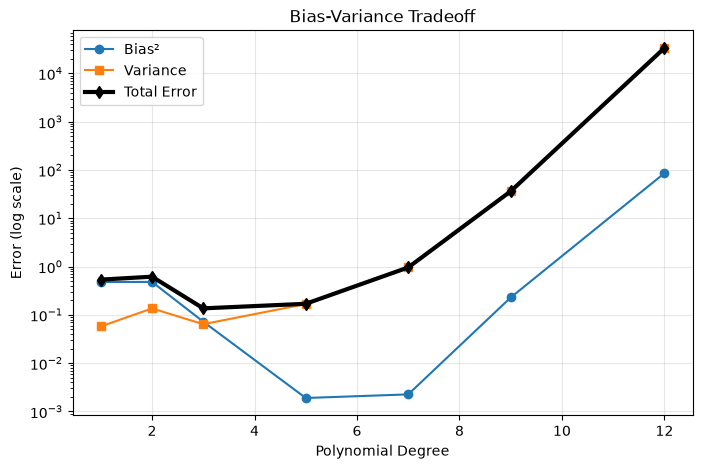

In [25]:
import matplotlib.pyplot as plt

degrees = list(results.keys())
bias = [results[d]['bias_sq'] for d in degrees]
var  = [results[d]['variance'] for d in degrees]
tot  = [results[d]['total_error'] for d in degrees]

plt.figure(figsize=(8, 5))
plt.plot(degrees, bias, 'o-', label='Bias²')
plt.plot(degrees, var,  's-', label='Variance')
plt.plot(degrees, tot,  'd-', label='Total Error', linewidth=3, color='black')
plt.yscale('log')  # log scale because degree 12 variance is 33,000!
plt.xlabel('Polynomial Degree')
plt.ylabel('Error (log scale)')
plt.title('Bias-Variance Tradeoff')
plt.legend()
plt.grid(alpha=0.3)
plt.show()